In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from scipy.stats import randint, uniform
from sklearn.tree import plot_tree



from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("train.csv",nrows=100000)

/tmp/ipykernel_11848/1659893828.py:1: DtypeWarning: Columns (28) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("train.csv",nrows=100000)


In [62]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

#df.sample(10)

In [ ]:
#Lo hacemos fuera del pipeline para que no interfiera por la descompensacion con el target
df = df.drop_duplicates()

### Funciones fuera del pipeline

In [ ]:
def eliminar_columnas_normalizacion(df):

    df = df.copy()

    

    # Eliminar filas con valores atípicos en columnas numéricas//*Como el score de validacion es bajo probamos a quitar este codigo
    #ya que los valores atipicos puede que tengan valor predictivo.
    """columnas_numericas = [
        col for col in df.select_dtypes(include="number").columns
        if df[col].nunique(dropna=True) > 2
    ]

    for col in columnas_numericas:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        limite_inferior = Q1 - 1.5 * IQR
        limite_superior = Q3 + 1.5 * IQR

        df = df[
            (df[col].isna()) |
            ((df[col] >= limite_inferior) & (df[col] <= limite_superior))
        ]"""

    # Columnas casi constantes
    columnas_casi_constantes = [
        col for col in df.columns
        if (
            df[col].value_counts(normalize=True, dropna=False).iloc[0] >= 0.99
            or df[col].dropna().nunique() <= 1
        )
    ]

    # Columnas con más del 95% de nulos
    porcentaje_nulos = df.isnull().mean()

    columnas_nulos_altos = (
        porcentaje_nulos[porcentaje_nulos > 0.95]
        .index
        .tolist()
    )

    columnas_a_eliminar = (
        set(columnas_nulos_altos)
        | set(columnas_casi_constantes)
    )

    # Eliminamos columnas con alta correlación con otras variables
    columnas_a_eliminar.add("OsBuild")
    columnas_a_eliminar.add("Census_OSSkuName")
    #Eliminamos columnas repetidas o que otras ya nos proporcionan la misma información
    columnas_a_eliminar.add("CountryIdentifier")

    df = df.drop(columns=columnas_a_eliminar, errors="ignore")

    float_cols_a_int = [
    col for col in df.select_dtypes(include="float").columns
    if ((df[col].dropna() % 1) == 0).all()]


    df[float_cols_a_int] = df[float_cols_a_int].astype("Int64")


    
    
    # Normalización de nombres de columnas: minúsculas, eliminación de espacios y unificacion de categorías
    df.columns = (
            df.columns
            .str.lower()
            .str.strip()
            .str.replace(" ", "_", regex=False)
        )

    df["smartscreen"] = (
    df["smartscreen"]
    .replace({
        "off": "Off",
        "OFF": "Off",
        "on": "On",
        "ON": "On"
    })
    )

    df["census_osedition"] = df["census_osedition"].replace({
    # Professional
    "ProfessionalN": "Professional",
    "ProfessionalEducation": "Professional",
    "ProfessionalEducationN": "Professional",

    # Core
    "CoreN": "Core",
    "CoreSingleLanguage": "Core",
    "CoreCountrySpecific": "Core",

    # Enterprise
    "EnterpriseN": "Enterprise",
    "EnterpriseS": "Enterprise",
    "EnterpriseSN": "Enterprise",

    # Education
    "EducationN": "Education",

    # Server
    "ServerStandard": "Server",
    "ServerStandardEval": "Server",
    "ServerDatacenterEval": "Server",
    "ServerSolution": "Server"})


    df["census_osinstalltypename"] = df["census_osinstalltypename"].replace({
    # Actualizaciones
    "UUPUpgrade": "Upgrade",

    # Instalaciones limpias
    "IBSClean": "Clean",
    "CleanPCRefresh": "Clean",

    # Restauración
    "Refresh": "Recovery",
    "Reset": "Recovery"})

   

    return df

In [ ]:
"""for col in df.columns:
    print(f"\n{col}:")
    print(f"{df[col].unique()}// {df[col].dtypes}")""""

In [ ]:
#Aquí vemos la columnas eliminadas para llevar un control
"""set(df.columns) - set(df_limpio.columns)""""

### Funciones pipeline


In [ ]:
def feature_engineering(X):

    X = X.copy()

    # 1. Separamos las versiones en 4 para mejorar la interpretabilidad del modelo.
    versiones = ["engineversion", "appversion", "avsigversion"]

    for col in versiones:
        partes = X[col].str.split(".", expand=True)

        for i, nombre in enumerate(["Major", "Minor", "Build", "Revision"]):
            if i < partes.shape[1]:
                X[f"{col}_{nombre.lower()}"] = partes[i].astype("Int64")

    X.drop(columns=versiones, inplace=True)

    # 2. Creamos la variable SecurityScore
    valores_protectores = ["RequireAdmin", "Warn", "Prompt", "Block", "On"]

    X["smartscreen_binary"] = (
        X["smartscreen"]
        .isin(valores_protectores)
        .astype(int)
    )

    X.drop(columns="smartscreen", inplace=True, errors="ignore")


    X["securityscore"] = (
        X["firewall"].fillna(0).astype(int)
        + X["census_issecurebootenabled"].fillna(0).astype(int)
        + X["smartscreen_binary"]
    )

    # 3. Creamos la variable HardwareScore

    # RAM
    X["ram_score"] = np.select(
        [
            X["census_totalphysicalram"].fillna(0).astype(float) < 4096,
            X["census_totalphysicalram"].fillna(0).astype(float) < 8192,
            X["census_totalphysicalram"].fillna(0).astype(float) < 16384
        ],
        [0, 1, 2],
        default=3
    )

    # Núcleos
    X["core_score"] = np.select(
        [
            X["census_processorcorecount"].fillna(0).astype(float) <= 2,
            X["census_processorcorecount"].fillna(0).astype(float) <= 4,
            X["census_processorcorecount"].fillna(0).astype(float) <= 8
        ],
        [0, 1, 2],
        default=3
    )

    # Tipo de disco
    X["disktype_score"] = (
        X["census_primarydisktypename"]
        .eq("SSD")
        .fillna(False)
        .astype(int)
    )

    # Capacidad del disco
    X["diskcapacity_score"] = np.select(
        [
            X["census_primarydisktotalcapacity"].fillna(0).astype(float) < 256000,
            X["census_primarydisktotalcapacity"].fillna(0).astype(float) < 512000
        ],
        [0, 1],
        default=2
    )

    # Hardware Score
    X["hardwarescore"] = (
        X["ram_score"]
        + X["core_score"]
        + X["disktype_score"]
        + X["diskcapacity_score"]
    )

    # Eliminamos variables auxiliares
    X.drop(
        columns=[
            "ram_score",
            "core_score",
            "diskcapacity_score"
        ],
        inplace=True,
        errors="ignore"
    )

    #4.Separamos los valores de la variable "OsBuildLab ya que agrupa diferente información"

    partes = X["osbuildlab"].str.split(".", expand=True)

    X["osbuild"] = partes[0]
    X["osrevision"] = partes[1]
    X["osarchitecture"] = partes[2]
    X["osrelease"] = partes[3]
    X["osbuilddate"] = partes[4]

    X.drop(columns=["osbuildlab"], inplace=True)

    return X

In [ ]:
#Separamos el dataset en X,y para entrenar y validar.
target_col = 'HasDetections'

X = df.drop(columns=[target_col, "MachineIdentifier"])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
# Creamos X temporal solo para saber qué columnas habrá
X_tmp = eliminar_columnas_normalizacion(X_train)
X_tmp = feature_engineering(X_tmp)

# Creamos listas usando X_tmp agrupando las variables según su categoría.
variables_binarias = [
    col for col in X_tmp.select_dtypes(include="number").columns
    if X_tmp[col].dropna().nunique() == 2
]

variables_categoricas = X_tmp.select_dtypes(
    include=["object", "category"]
).columns.tolist()

variables_numericas = [
    col for col in X_tmp.select_dtypes(include="number").columns
    if col not in variables_binarias
]

#Creamos los pipelines para cada categoría 

numeric_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer(n_neighbors=5))
])

binary_pipeline = Pipeline([
    ("imputer", KNNImputer(n_neighbors=5)),
    ("round", FunctionTransformer(lambda X: np.rint(X).astype(int), validate=False))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=0.01
    ))
])

#Creamos el preprocesador que aunará todas estas transformaciones.

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, variables_numericas),
    ("bin", binary_pipeline, variables_binarias),
    ("cat", categorical_pipeline, variables_categoricas)
])


In [ ]:
#Entrenamos un arbol normal para valorar la importancia de las variables
X_sample = X_train.sample(n=50000, random_state=42)
y_sample = y_train.loc[X_sample.index]

pipeline = Pipeline([
    ("limpieza", FunctionTransformer(eliminar_columnas_normalizacion, validate=False)),
    ("feature_engineering", FunctionTransformer(feature_engineering, validate=False)),
    ("preprocessor", preprocessor),
    ("modelo", RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=4,
        class_weight="balanced"
    ))
])

pipeline.fit(X_sample, y_sample)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('limpieza', ...), ('feature_engineering', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function eli...x7e9b1f6b89a0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arg

In [ ]:
#analizamos importancia de variables segun el arbol

rf = pipeline.named_steps["modelo"]
pre = pipeline.named_steps["preprocessor"]

importancias = rf.feature_importances_

n_num = len(variables_numericas)
n_bin = len(variables_binarias)

# Nombres numéricas y binarias
nombres_num = variables_numericas
nombres_bin = variables_binarias

# Nombres categóricas tras OneHotEncoder
onehot = pre.named_transformers_["cat"].named_steps["onehot"]
nombres_cat = onehot.get_feature_names_out(variables_categoricas).tolist()

# Todos los nombres transformados
feature_names = nombres_num + nombres_bin + nombres_cat

importancias_df = pd.DataFrame({
    "variable_transformada": feature_names,
    "importancia": importancias
}).sort_values("importancia", ascending=False)

print(importancias_df.head(30))

                                variable_transformada  importancia
1                           avproductstatesidentifier     0.092319
2                                 avproductsinstalled     0.078208
55                                 smartscreen_binary     0.043097
31                                engineversion_build     0.040631
38                                 avsigversion_minor     0.039201
35                                   appversion_build     0.031001
16                   census_systemvolumetotalcapacity     0.027832
18  census_internalprimarydiagonaldisplaysizeininches     0.026989
39                                 avsigversion_build     0.026710
15                    census_primarydisktotalcapacity     0.023644
14                    census_processormodelidentifier     0.022263
4                                      cityidentifier     0.020177
27                   census_firmwareversionidentifier     0.020076
11                          census_oemmodelidentifier     0.01

In [ ]:
#transformamos las variables transformadas y volvemos a las variables originales agrupándolas.
def variable_original(nombre):
    for col in variables_categoricas:
        if nombre.startswith(col + "_"):
            return col
    return nombre

importancias_df["variable_original"] = (
    importancias_df["variable_transformada"].apply(variable_original)
)

importancias_originales = (
    importancias_df
    .groupby("variable_original", as_index=False)["importancia"]
    .sum()
    .sort_values("importancia", ascending=False)
)

print(importancias_originales.head(30))

                                    variable_original  importancia
6                           avproductstatesidentifier     0.092319
5                                 avproductsinstalled     0.078208
78                                 smartscreen_binary     0.043097
51                                engineversion_build     0.040631
9                                  avsigversion_minor     0.039201
0                                    appversion_build     0.031001
46                   census_systemvolumetotalcapacity     0.027832
20  census_internalprimarydiagonaldisplaysizeininches     0.026989
7                                  avsigversion_build     0.026710
41                    census_primarydisktotalcapacity     0.023644
45                    census_processormodelidentifier     0.022263
36                           census_osinstalltypename     0.020457
49                                     cityidentifier     0.020177
14                   census_firmwareversionidentifier     0.02

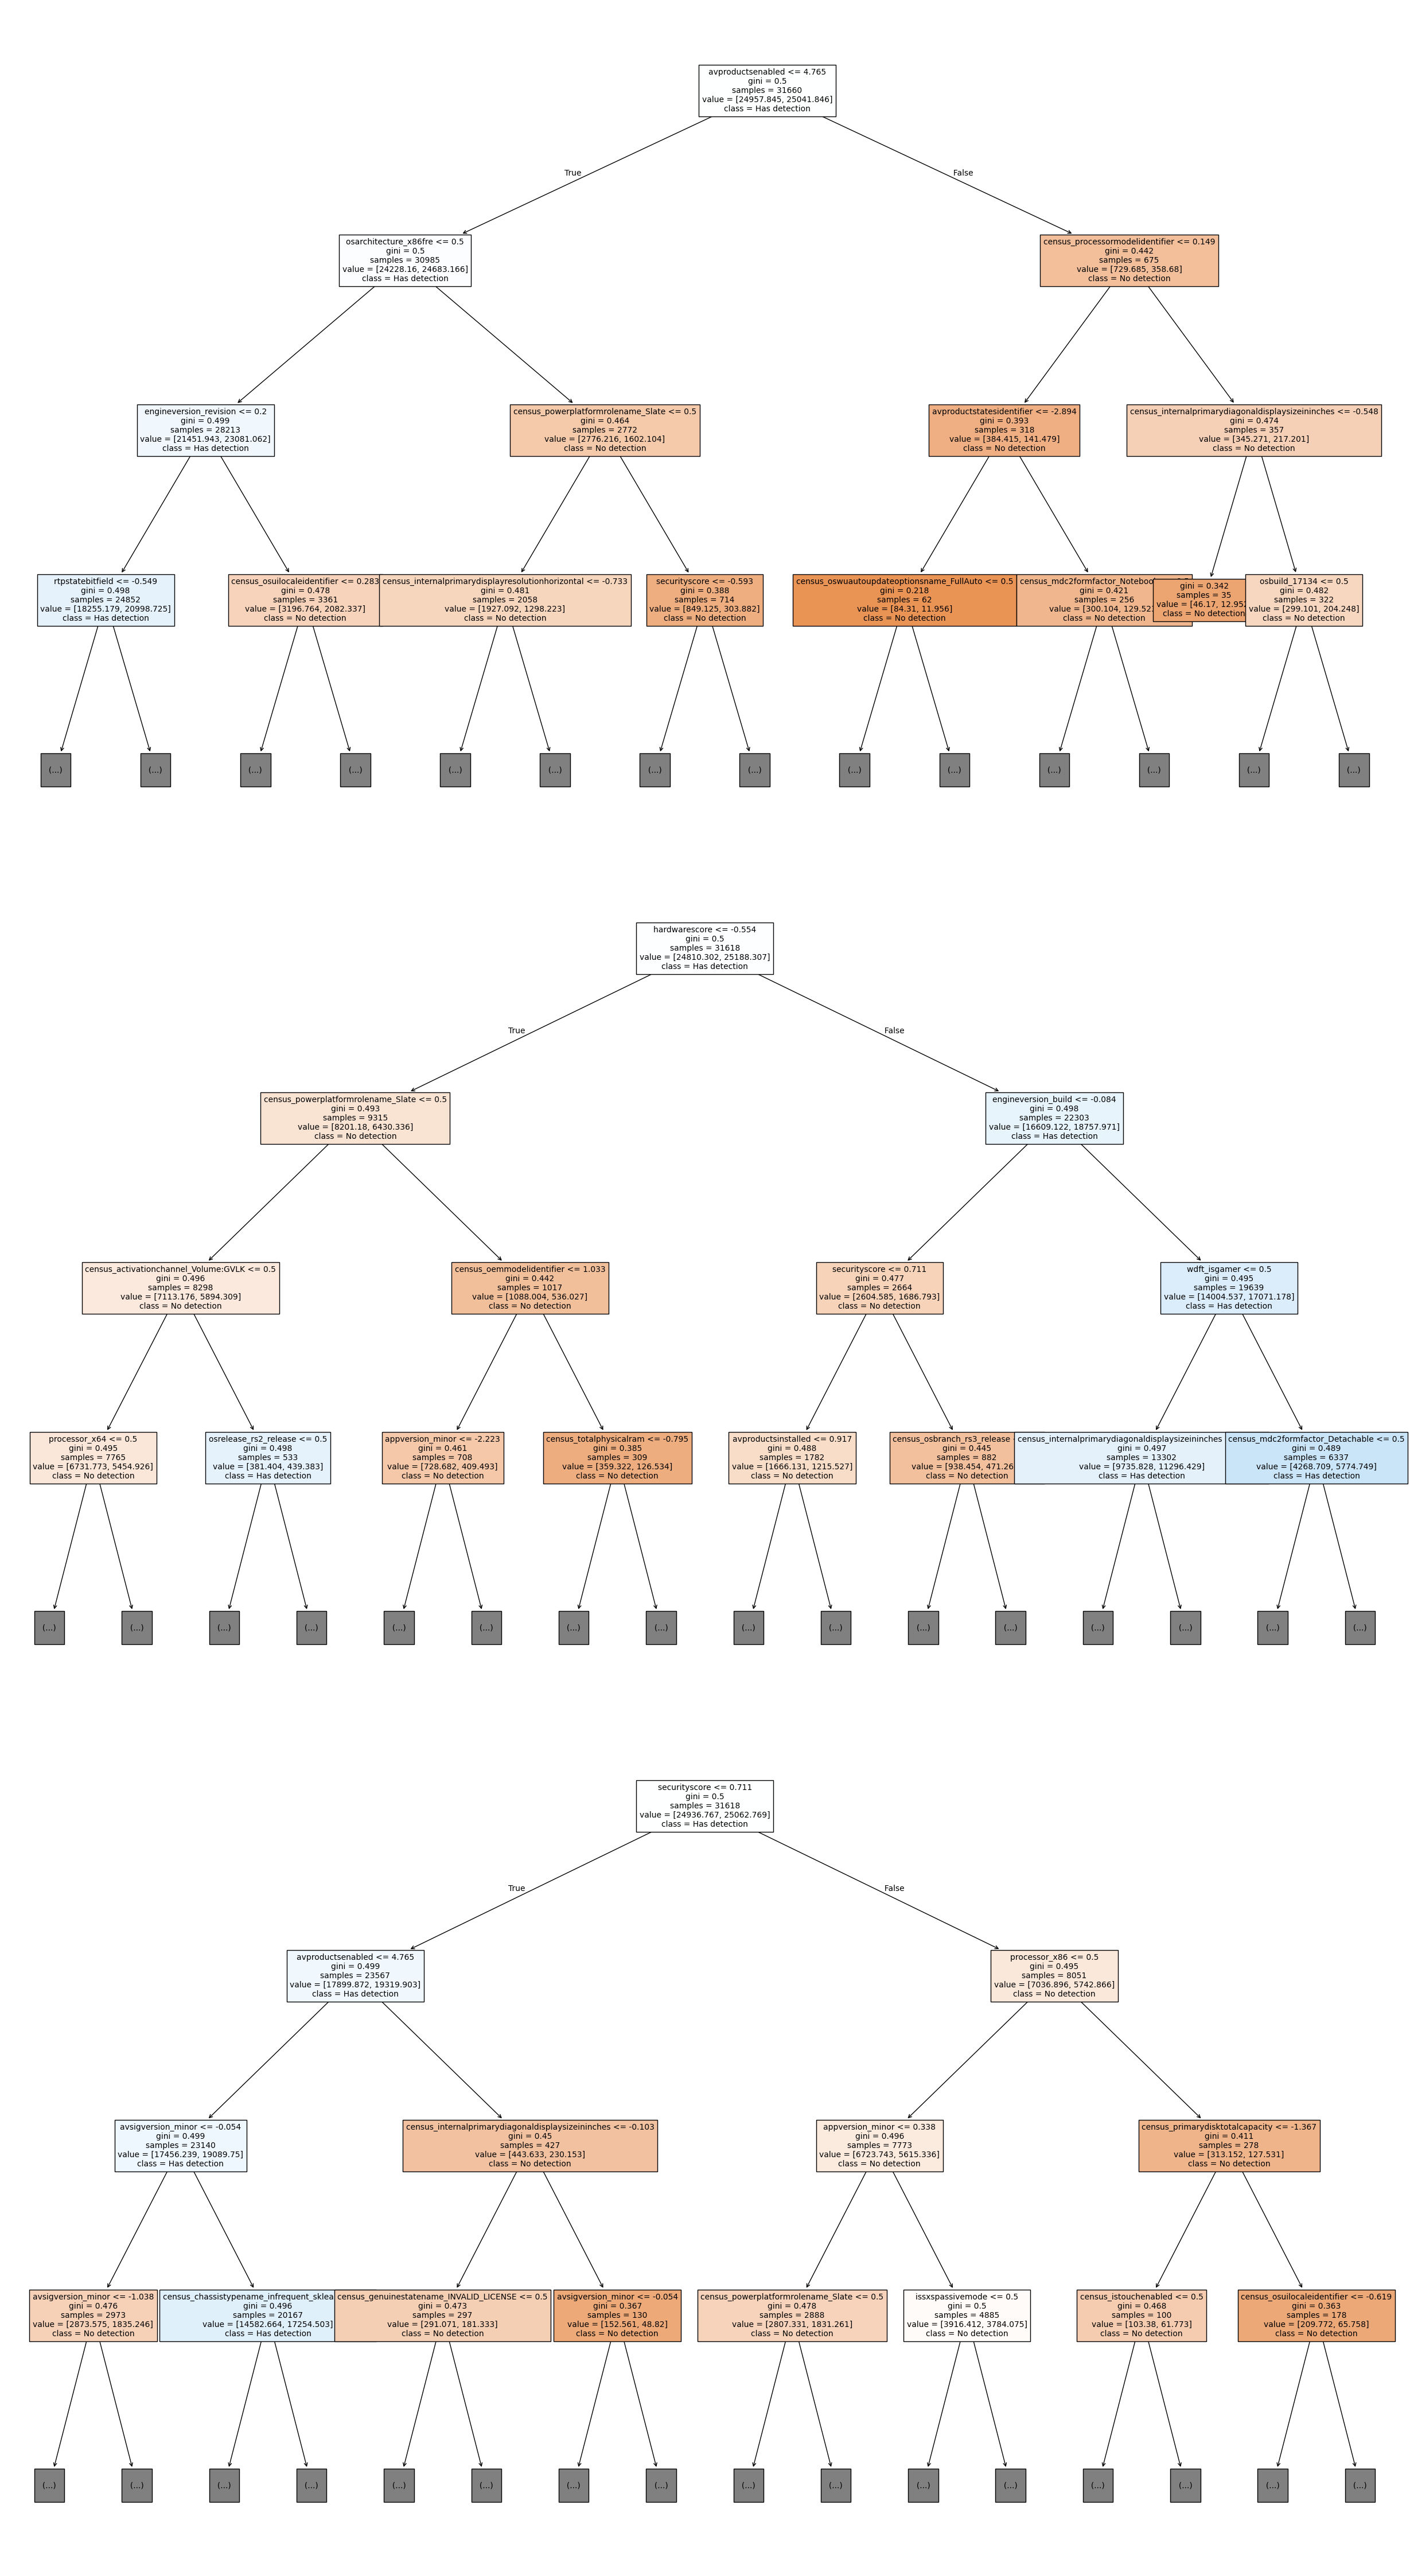

In [ ]:
#elegimos 3 arboles al azar para entender las importancias a traves de su representación

rf = pipeline.named_steps["modelo"]
pre = pipeline.named_steps["preprocessor"]

num_names = variables_numericas
bin_names = variables_binarias

cat_names = pre.named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(
    variables_categoricas
)

feature_names = list(num_names) + list(bin_names) + list(cat_names)


trees = [4, 20,48]

fig, axes = plt.subplots(len(trees), 1, figsize=(25, 15 * len(trees)))

for i, tree_idx in enumerate(trees):
    plot_tree(
        rf.estimators_[tree_idx],
        max_depth=3,
        filled=True,
        feature_names=feature_names,
        class_names = ["No detection", "Has detection"],
        fontsize=10,
        ax=axes[i]
    )

plt.tight_layout()
plt.show()

,Resultado
Accuracy,0.616850
Balanced accuracy,0.616937
Precision,0.603290
Recall / Sensibilidad,0.679351
F1-score,0.639066
ROC AUC,0.667264


Classification report:
              precision    recall  f1-score   support

           0       0.63      0.55      0.59     10014
           1       0.60      0.68      0.64      9986

    accuracy                           0.62     20000
   macro avg       0.62      0.62      0.62     20000
weighted avg       0.62      0.62      0.62     20000



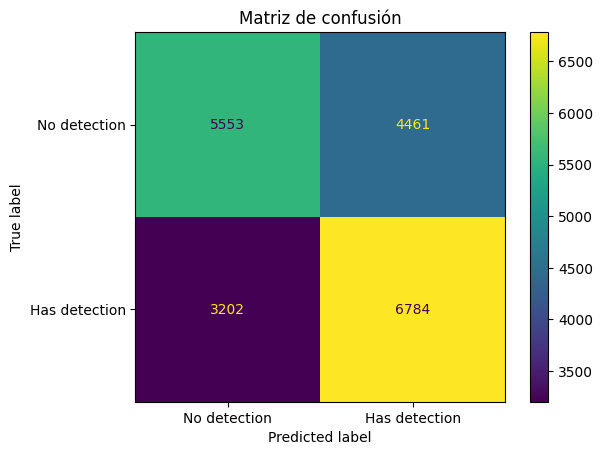

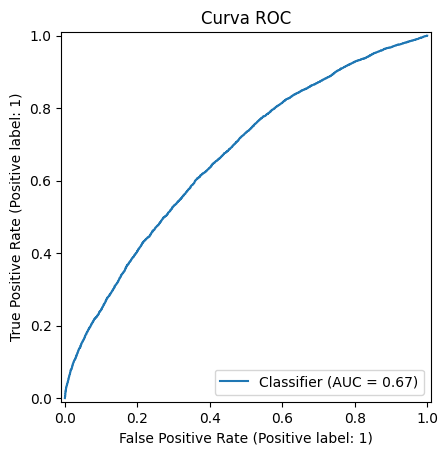

In [ ]:
#Analizamos las metricas principales creando una matriz de confusion y representando la curva ROC.

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)

#Hacemos predicciones
y_pred = pipeline.predict(X_test)

#Probabilidades para curva ROC
y_proba = pipeline.predict_proba(X_test)[:, 1]

#Creamos un diccionario con las métricas principales
metricas = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall / Sensibilidad": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "ROC AUC": roc_auc_score(y_test, y_proba)
}

metricas_df = pd.DataFrame(metricas, index=["Resultado"]).T
display(metricas_df)


#Hacemos un Classification report

print("Classification report:")
print(classification_report(y_test, y_pred))

#Creamos la matriz de confusión.

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No detection", "Has detection"]
)

disp.plot()
plt.title("Matriz de confusión")
plt.show()

#Creamos la curva ROC

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("Curva ROC")
plt.show()

### Elección del mejor modelo e hiperparametros

In [ ]:
#Volvemos a cargar el dataset para buscar el modelo e hiperparametros óptimos.
df = pd.read_csv("train.csv",nrows=100000)

/tmp/ipykernel_11848/1659893828.py:1: DtypeWarning: Columns (28) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("train.csv",nrows=100000)


In [ ]:
#Nos quedamos solo con las 40 variables que mas influyen en el target para que la iteración sea mas rápida.

top40 = importancias_originales["variable_original"].head(40).tolist()

df_fe = eliminar_columnas_normalizacion(df)
df_fe = feature_engineering(df_fe)

X_top40 = df_fe[top40]
y = df_fe["hasdetections"]   

In [ ]:
#Volvemos a hacer split.
X_train_top40, X_test_top40, y_train, y_test = train_test_split(
    X_top40,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)



In [ ]:
#Volvemos a crear listas.
variables_binarias = [
    col for col in X_train_top40.select_dtypes(include="number").columns
    if X_train_top40[col].dropna().nunique() == 2
]

variables_categoricas = X_train_top40.select_dtypes(
    include=["object", "category"]
).columns.tolist()

variables_numericas = [
    col for col in X_train_top40.select_dtypes(include="number").columns
    if col not in variables_binarias
]

In [ ]:
#Especificamos como se va a transformar cada una de las listas de variables creadas anteriormente y creamos una función para 
#que redondee el resultado de aplicar KNN imputer a variables binarias.

def redondear_binarias(X):
    return np.rint(X).astype(int)

numeric_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer(n_neighbors=5))
])

binary_pipeline = Pipeline([
    ("imputer", KNNImputer(n_neighbors=5)),
    ("round", FunctionTransformer(redondear_binarias, validate=False))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=0.01
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, variables_numericas),
    ("bin", binary_pipeline, variables_binarias),
    ("cat", categorical_pipeline, variables_categoricas)
])

In [48]:
# Instanciamos los modelos y los almacenamos en un diccionario
# junto con los hiperparámetros que queramos optimizar 
classifiers = {
    "DecisionTree": {
        "model": DecisionTreeClassifier(random_state=42),
        "hiperparameters": {
            "modelo__criterion": ["gini", "entropy"],
            "modelo__max_depth": randint(3, 25),
            "modelo__min_samples_leaf": randint(10, 200),
            "modelo__min_samples_split": randint(20, 300)
        }
    },

    "RandomForest": {
        "model": RandomForestClassifier(
            n_jobs=4,
            random_state=42,
            class_weight="balanced"
        ),
        "hiperparameters": {
            "modelo__criterion": ["gini", "entropy"],
            "modelo__max_depth": randint(5, 30),
            "modelo__min_samples_leaf": randint(5, 100),
            "modelo__min_samples_split": randint(10, 200),
            "modelo__n_estimators": randint(100, 400),
            "modelo__max_features": ["sqrt", "log2"]
        }
    },

    "GradientBoosting": {
        "model": GradientBoostingClassifier(random_state=42),
        "hiperparameters": {
            "modelo__max_depth": randint(2, 6),
            "modelo__min_samples_leaf": randint(10, 150),
            "modelo__min_samples_split": randint(20, 300),
            "modelo__learning_rate": [0.2, 0.1, 0.05, 0.01],
            "modelo__n_estimators": randint(100, 400),
            "modelo__subsample": uniform(0.7, 0.3)
        }
    },

    "XGBoost": {
        "model": XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_jobs=4,
            random_state=42
        ),
        "hiperparameters": {
            "modelo__max_depth": randint(3, 9),
            "modelo__n_estimators": randint(100, 500),
            "modelo__learning_rate": [0.2, 0.1, 0.05, 0.01],
            "modelo__subsample": uniform(0.7, 0.3),
            "modelo__colsample_bytree": uniform(0.6, 0.4),
            "modelo__min_child_weight": randint(1, 10),
            "modelo__gamma": uniform(0, 5)
        }
    }
}

In [49]:
# Iteramos sobre el diccionario anterior, y mediante Random Search 
# vamos optimizando cada uno de los modelos y guardando los resultados
# en un pd.DataFrame

random_search_output = []
best_estimators = {}

for clf_name, clf_info in classifiers.items():
    print(clf_name)

    pipeline_modelo = Pipeline([
        ("preprocessor", preprocessor),
        ("modelo", clf_info["model"])
    ])

    clf_random_search = RandomizedSearchCV(
        estimator=pipeline_modelo,
        param_distributions=clf_info["hiperparameters"],
        n_iter=15,
        cv=3,
        scoring="roc_auc",
        return_train_score=False,
        refit=True,
        n_jobs=4,
        verbose=2,
        random_state=42
    )

    clf_random_search.fit(X_train_top40, y_train)

    df_output = pd.DataFrame(clf_random_search.cv_results_)
    df_output["clf"] = clf_name
    random_search_output.append(df_output)

    best_estimators[clf_name] = clf_random_search.best_estimator_

DecisionTree
Fitting 3 folds for each of 15 candidates, totalling 45 fits
[CV] END modelo__criterion=gini, modelo__max_depth=22, modelo__min_samples_leaf=102, modelo__min_samples_split=290; total time= 2.3min
[CV] END modelo__criterion=gini, modelo__max_depth=10, modelo__min_samples_leaf=198, modelo__min_samples_split=40; total time= 2.3min
[CV] END modelo__criterion=gini, modelo__max_depth=22, modelo__min_samples_leaf=102, modelo__min_samples_split=290; total time= 2.4min
[CV] END modelo__criterion=gini, modelo__max_depth=22, modelo__min_samples_leaf=102, modelo__min_samples_split=290; total time= 2.4min
[CV] END modelo__criterion=gini, modelo__max_depth=10, modelo__min_samples_leaf=198, modelo__min_samples_split=40; total time= 2.2min
[CV] END modelo__criterion=gini, modelo__max_depth=10, modelo__min_samples_leaf=198, modelo__min_samples_split=40; total time= 2.2min
[CV] END modelo__criterion=gini, modelo__max_depth=21, modelo__min_samples_leaf=84, modelo__min_samples_split=107; tota

In [51]:
import joblib

joblib.dump(best_estimators, "best_estimators_top40.pkl")

['best_estimators_top40.pkl']

In [ ]:
# Concatenamos todos los resultados para cada modelo
random_search_df = pd.concat(random_search_output, ignore_index=True)

joblib.dump(random_search_df, "random_search_results_top40.pkl")

['random_search_results_top40.pkl']

In [55]:
random_search_df.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__min_samples_split,params,split0_test_score,...,std_test_score,rank_test_score,clf,param_modelo__max_features,param_modelo__n_estimators,param_modelo__learning_rate,param_modelo__subsample,param_modelo__colsample_bytree,param_modelo__gamma,param_modelo__min_child_weight
0,98.039987,3.479845,44.933644,5.480039,gini,22,102.0,290.0,"{'modelo__criterion': 'gini', 'modelo__max_dep...",0.643139,...,0.002699,6,DecisionTree,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,93.224347,1.891499,42.365262,0.872014,gini,10,198.0,40.0,"{'modelo__criterion': 'gini', 'modelo__max_dep...",0.646385,...,0.001251,1,DecisionTree,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,91.608874,4.421143,42.024762,2.771880,gini,21,84.0,107.0,"{'modelo__criterion': 'gini', 'modelo__max_dep...",0.636479,...,0.002288,13,DecisionTree,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,88.994459,1.490798,37.560115,1.162836,gini,6,113.0,171.0,"{'modelo__criterion': 'gini', 'modelo__max_dep...",0.642212,...,0.004565,12,DecisionTree,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,65.038753,1.653781,31.066227,0.795823,gini,24,62.0,277.0,"{'modelo__criterion': 'gini', 'modelo__max_dep...",0.641105,...,0.003033,11,DecisionTree,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [58]:

split_test_score_columns = ['split0_test_score', 'split1_test_score', 'split2_test_score']

df_results = random_search_df[
    ['clf', 'rank_test_score', 'mean_test_score', 'std_test_score', 'params']
    + split_test_score_columns]
df_results.sample(10)

,clf,rank_test_score,mean_test_score,std_test_score,params,split0_test_score,split1_test_score,split2_test_score
57,XGBoost,15,0.663874,0.001626,{'modelo__colsample_bytree': 0.908897907718663...,0.664727,0.661597,0.665297
55,XGBoost,10,0.674947,0.002453,{'modelo__colsample_bytree': 0.984468809739739...,0.677738,0.671768,0.675336
43,GradientBoosting,12,0.668279,0.002137,"{'modelo__learning_rate': 0.01, 'modelo__max_d...",0.669542,0.665269,0.670025
20,RandomForest,3,0.667929,0.003116,"{'modelo__criterion': 'gini', 'modelo__max_dep...",0.669046,0.663679,0.671061
52,XGBoost,12,0.673546,0.001718,{'modelo__colsample_bytree': 0.776060997495840...,0.675181,0.671172,0.674284
34,GradientBoosting,6,0.673895,0.002967,"{'modelo__learning_rate': 0.1, 'modelo__max_de...",0.676096,0.669701,0.675890
37,GradientBoosting,14,0.665032,0.003170,"{'modelo__learning_rate': 0.05, 'modelo__max_d...",0.667073,0.660555,0.667468
22,RandomForest,7,0.664820,0.003397,"{'modelo__criterion': 'entropy', 'modelo__max_...",0.666136,0.660162,0.668163
44,GradientBoosting,9,0.670507,0.002876,"{'modelo__learning_rate': 0.2, 'modelo__max_de...",0.673087,0.666494,0.671941
45,XGBoost,3,0.679162,0.002839,{'modelo__colsample_bytree': 0.749816047538945...,0.682107,0.675325,0.680053


In [56]:
# Nos quedamos con el mejor modelo de cada tipo
df_best = (
    df_results
    .query('rank_test_score == 1')
    .drop_duplicates(['clf', 'rank_test_score'])
    .sort_values('mean_test_score', ascending = False)
    .reset_index(drop = True)
)
df_best

,clf,rank_test_score,mean_test_score,std_test_score,params,split0_test_score,split1_test_score,split2_test_score
0,XGBoost,1,0.679918,0.002875,{'modelo__colsample_bytree': 0.759944388686102...,0.682516,0.675910,0.681327
1,GradientBoosting,1,0.678490,0.002129,"{'modelo__learning_rate': 0.05, 'modelo__max_d...",0.679953,0.675480,0.680038
2,RandomForest,1,0.671222,0.002817,"{'modelo__criterion': 'gini', 'modelo__max_dep...",0.671951,0.667467,0.674249
3,DecisionTree,1,0.645098,0.001251,"{'modelo__criterion': 'gini', 'modelo__max_dep...",0.646385,0.643404,0.645506


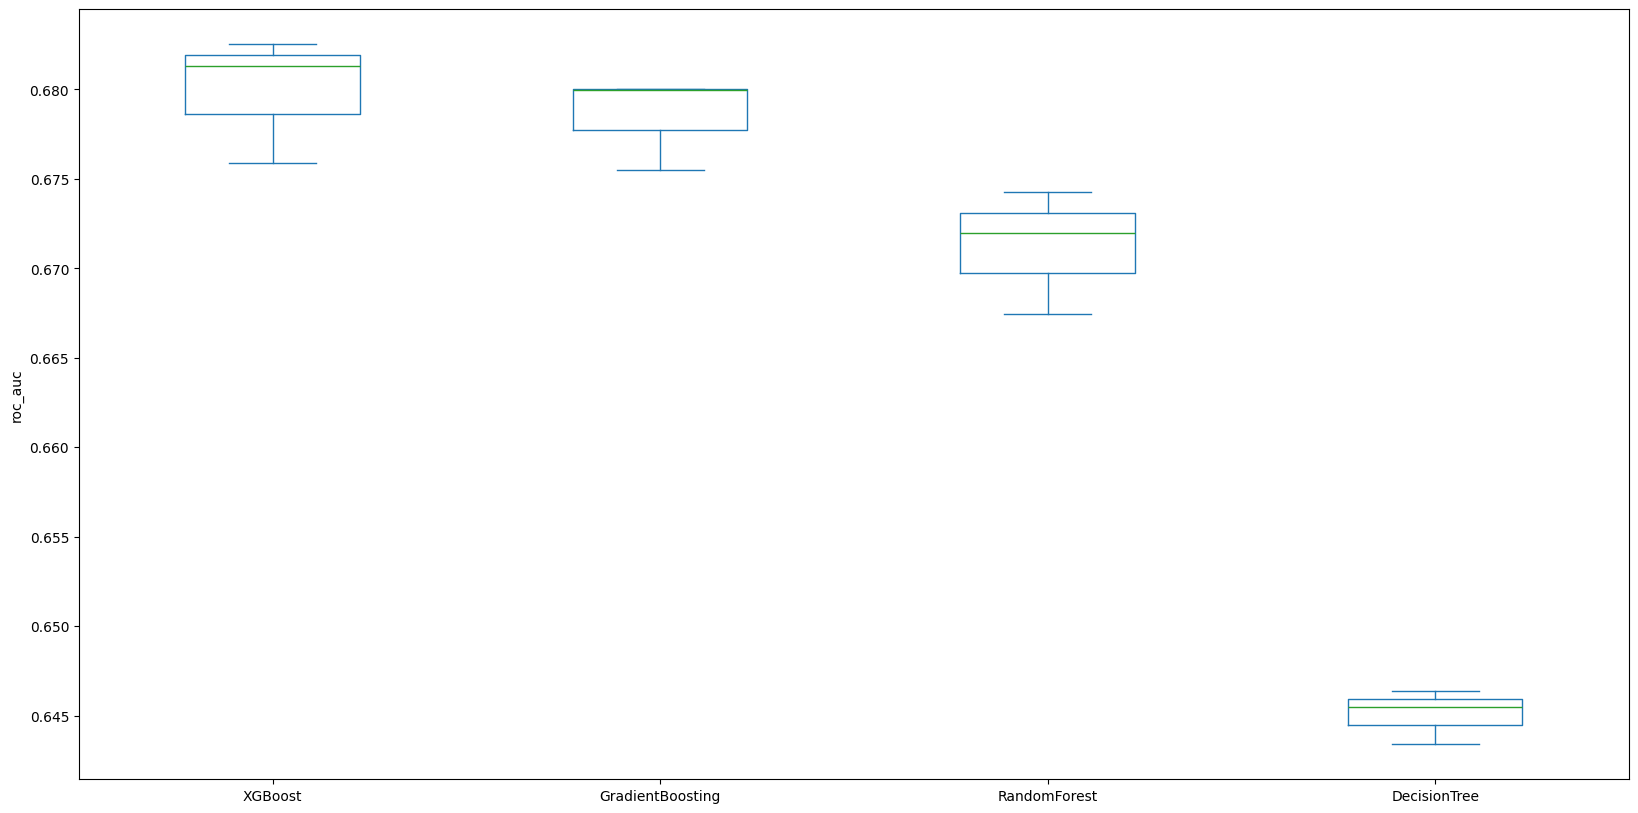

In [69]:
# Boxplot de los scores en test del mejor modelo de cada tipo
df_best.index = df_best['clf']
df_best[split_test_score_columns].T.plot(kind = 'box', figsize = (20, 10))
plt.ylabel("roc_auc")
plt.show()

In [ ]:
#Vemos los hiperparametros del mejor modelo
from pprint import pprint

pprint(df_best.loc[df_best["clf"] == "XGBoost", "params"].iloc[0])

{'modelo__colsample_bytree': np.float64(0.7599443886861021),
 'modelo__gamma': np.float64(0.23332831606807714),
 'modelo__learning_rate': 0.01,
 'modelo__max_depth': 8,
 'modelo__min_child_weight': 3,
 'modelo__n_estimators': 463,
 'modelo__subsample': np.float64(0.8542703315240834)}


In [73]:
#Volvemos a cargar el dataset para entrenar con XGBoost
df = pd.read_csv("train.csv",nrows=100000)

/tmp/ipykernel_11848/379881000.py:2: DtypeWarning: Columns (28) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("train.csv",nrows=100000)


In [74]:
#Lo hacemos fuera del pipeline para que no interfiera por la descompensacion con el target
df = df.drop_duplicates()

In [75]:
#Separamos el dataset en X,y para entrenar y validar.
target_col = 'HasDetections'

X = df.drop(columns=[target_col, "MachineIdentifier"])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [76]:
#Volvemos a crear listas.
variables_binarias = [
    col for col in X_train_top40.select_dtypes(include="number").columns
    if X_train_top40[col].dropna().nunique() == 2
]

variables_categoricas = X_train_top40.select_dtypes(
    include=["object", "category"]
).columns.tolist()

variables_numericas = [
    col for col in X_train_top40.select_dtypes(include="number").columns
    if col not in variables_binarias
]

In [77]:
#Especificamos como se va a transformar cada una de las listas de variables creadas anteriormente y creamos una función para 
#que redondee el resultado de aplicar KNN imputer a variables binarias.

def redondear_binarias(X):
    return np.rint(X).astype(int)

numeric_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer(n_neighbors=5))
])

binary_pipeline = Pipeline([
    ("imputer", KNNImputer(n_neighbors=5)),
    ("round", FunctionTransformer(redondear_binarias, validate=False))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=0.01
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, variables_numericas),
    ("bin", binary_pipeline, variables_binarias),
    ("cat", categorical_pipeline, variables_categoricas)
])

In [79]:
#Entrenamos el modelo con los hiperparametros.
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=4,

    colsample_bytree=0.7599443886861021,
    gamma=0.23332831606807714,
    learning_rate=0.01,
    max_depth=8,
    min_child_weight=3,
    n_estimators=463,
    subsample=0.8542703315240834
)

In [80]:
pipeline_xgb = Pipeline([
    ("limpieza", FunctionTransformer(eliminar_columnas_normalizacion, validate=False)),
    ("feature_engineering", FunctionTransformer(feature_engineering, validate=False)),
    ("preprocessor", preprocessor),
    ("modelo",xgb_model)
])

pipeline_xgb.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('limpieza', ...), ('feature_engineering', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function eli...x7e9b1f6b89a0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arg

,Resultado
Accuracy,0.628250
Balanced accuracy,0.628319
Precision,0.616113
Recall / Sensibilidad,0.677749
F1-score,0.645463
ROC AUC,0.682359


Classification report:
              precision    recall  f1-score   support

           0       0.64      0.58      0.61     10014
           1       0.62      0.68      0.65      9986

    accuracy                           0.63     20000
   macro avg       0.63      0.63      0.63     20000
weighted avg       0.63      0.63      0.63     20000



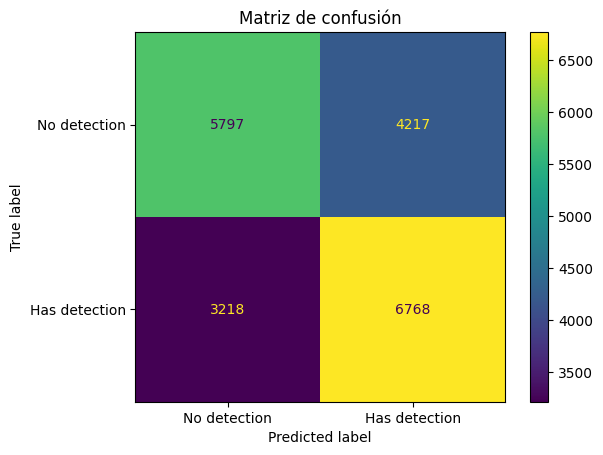

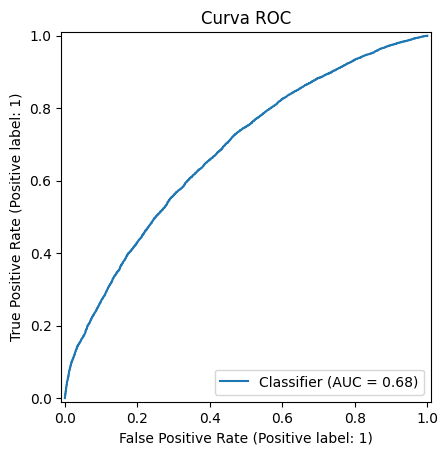

In [81]:
#Analizamos las metricas principales creando una matriz de confusion y representando la curva ROC.

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)

#Hacemos predicciones
y_pred = pipeline_xgb.predict(X_test)

#Probabilidades para curva ROC
y_proba = pipeline_xgb.predict_proba(X_test)[:, 1]

#Creamos un diccionario con las métricas principales
metricas = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall / Sensibilidad": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "ROC AUC": roc_auc_score(y_test, y_proba)
}

metricas_df = pd.DataFrame(metricas, index=["Resultado"]).T
display(metricas_df)


#Hacemos un Classification report

print("Classification report:")
print(classification_report(y_test, y_pred))

#Creamos la matriz de confusión.

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No detection", "Has detection"]
)

disp.plot()
plt.title("Matriz de confusión")
plt.show()

#Creamos la curva ROC

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("Curva ROC")
plt.show()

In [82]:
joblib.dump(pipeline_xgb, "modelo_xgboost.pkl")

['modelo_xgboost.pkl']

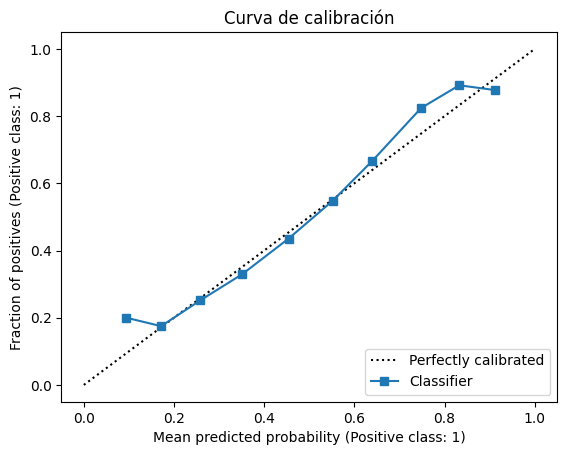

In [ ]:
# vemos si el modelo esta calibrado
from sklearn.calibration import calibration_curve, CalibrationDisplay

CalibrationDisplay.from_predictions(
    y_test,
    y_proba,
    n_bins=10
)

plt.title("Curva de calibración")
plt.show()

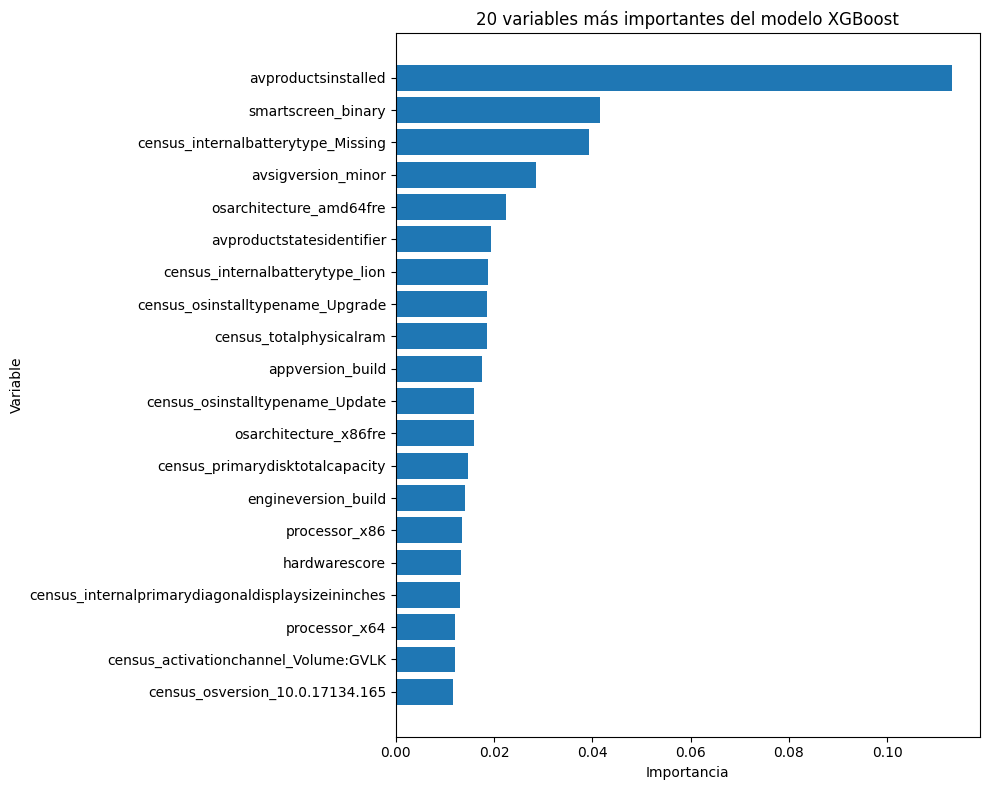

In [ ]:
#vemos las importancias del XGBoost

best_model = best_estimators["XGBoost"]
xgb = best_model.named_steps["modelo"]
pre = best_model.named_steps["preprocessor"]

num_names = list(pre.transformers_[0][2])
bin_names = list(pre.transformers_[1][2])

cat_pipeline = pre.named_transformers_["cat"]
onehot = cat_pipeline.named_steps["onehot"]
cat_cols = list(pre.transformers_[2][2])
cat_names = list(onehot.get_feature_names_out(cat_cols))

feature_names = num_names + bin_names + cat_names

importancias = pd.DataFrame({
    "variable": feature_names,
    "importancia": xgb.feature_importances_
})

top20 = importancias.sort_values("importancia", ascending=False).head(20)

plt.figure(figsize=(10, 8))
plt.barh(top20["variable"], top20["importancia"])
plt.gca().invert_yaxis()
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.title("20 variables más importantes del modelo XGBoost")
plt.tight_layout()
plt.show()

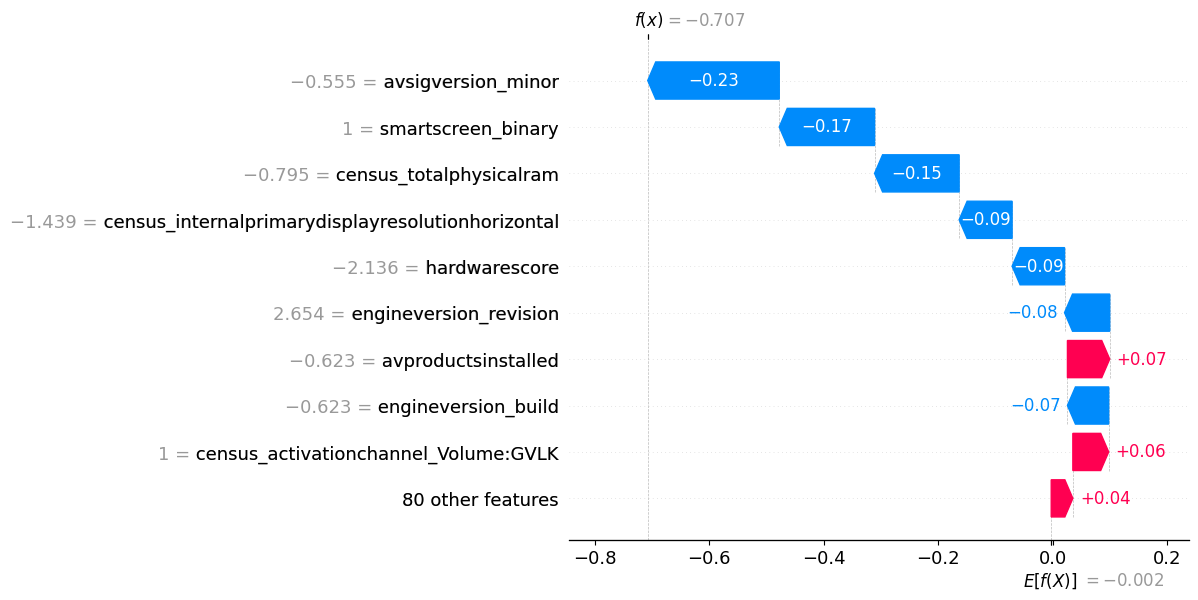

In [ ]:
#interpretamos los resultados con shap para saber cuanto contribuye cada variable en la detección en un caso concreto

import shap

best_model = best_estimators["XGBoost"]

preprocessor = best_model.named_steps["preprocessor"]
xgb = best_model.named_steps["modelo"]

X_test_fe = eliminar_columnas_normalizacion(X_test)
X_test_fe = feature_engineering(X_test_fe)

X_test_preprocesado = preprocessor.transform(X_test_fe)

# Nombres manuales
num_names = list(preprocessor.transformers_[0][2])
bin_names = list(preprocessor.transformers_[1][2])

cat_pipeline = preprocessor.named_transformers_["cat"]
onehot = cat_pipeline.named_steps["onehot"]
cat_cols = list(preprocessor.transformers_[2][2])
cat_names = list(onehot.get_feature_names_out(cat_cols))

feature_names = num_names + bin_names + cat_names

# Pasar la matriz a DataFrame con nombres
X_test_preprocesado_df = pd.DataFrame(
    X_test_preprocesado,
    columns=feature_names
)

explainer = shap.TreeExplainer(xgb)
shap_values = explainer(X_test_preprocesado_df)

shap.plots.waterfall(shap_values[0])

### Posible aplicación del modelo en la vida real

##### Una posible aplicación de este modelo en un entorno real sería su integración en el sistema de ciberseguridad de una gran corporación para analizar de forma automática el estado de los equipos. Cuando el modelo detecte que un dispositivo presenta una alta probabilidad de estar comprometido, se generaría una alerta inmediata para el equipo de seguridad. Además, el sistema podría ejecutar acciones automáticas, como actualizar las definiciones del antivirus, aplicar parches de seguridad, reforzar la configuración del equipo o aislar temporalmente el dispositivo de la red. De este modo, se reduciría el tiempo de respuesta ante posibles amenazas y se minimizaría el riesgo de propagación del malware dentro de la organización.